# Michaelis-Menten: Tau Hybrid Convergence Study
***
## Setup the Environment
***

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
from copy import deepcopy
sys.path.insert(1, os.path.abspath(os.path.join(os.getcwd(), '../')))

In [3]:
import gillespy3d_pp as gillespy2

In [4]:
import matplotlib.pyplot as plt

In [5]:
gillespy2.__file__

'/Users/anisgolriz/Desktop/GillesPy3D/simulation_lib/gillespy3d_pp/__init__.py'

In [6]:
def create_michaelis_menten(sub0=301, enz0=120, rate1=0.0017, rate2=0.5, rate3=0.1, end_t=100):
    # Initialize Model
    model = gillespy2.Model(name="Michaelis_Menten",)

    # Define Variables (GillesPy2.Species)
    A = gillespy2.Species(name='Substrate', initial_value=sub0,mode='dynamic')
    B = gillespy2.Species(name='Enzyme', initial_value=enz0,mode='dynamic')
    C = gillespy2.Species(name='Enzyme_Substrate_Complex', initial_value=0,mode='dynamic')
    D = gillespy2.Species(name='Product', initial_value=0,mode='dynamic')

    # Add Variables to Model
    model.add_species([A, B, C, D])

    # Define Parameters
    p1 = gillespy2.Parameter(name='rate1', expression=rate1)
    p2 = gillespy2.Parameter(name='rate2', expression=rate2)
    p3 = gillespy2.Parameter(name='rate3', expression=rate3)

    # Add Parameters to Model
    model.add_parameter([p1, p2, p3])

    # Define Reactions
    r1 = gillespy2.Reaction(
        name="r1", reactants={'Substrate': 1, 'Enzyme': 1},
        products={'Enzyme_Substrate_Complex': 1}, rate='rate1'
    )
    r2 = gillespy2.Reaction(
        name="r2", reactants={'Enzyme_Substrate_Complex': 1},
        products={'Substrate': 1, 'Enzyme': 1}, rate='rate2'
    )
    r3 = gillespy2.Reaction(
        name="r3", reactants={'Enzyme_Substrate_Complex': 1},
        products={'Enzyme': 1, 'Product': 1}, rate='rate3'
    )
    # Add Reactions to Model
    model.add_reaction([r1, r2, r3])

    # Define Timespan
    tspan = gillespy2.TimeSpan.linspace(end_t=end_t, num_points=int(end_t) + 1)

    # Set Model Timespan
    model.timespan(tspan)
    return model

### Instantiate the Model

In [7]:
# --- WITHOUT Avogadro's number ---
sub0, enz0 = 301, 120
rate1, rate2, rate3 = 0.0017, 0.5, 0.1
end_t = 10

model = create_michaelis_menten(sub0, enz0, rate1, rate2, rate3, end_t)

***
## Convergence Study
***

### Config

In [8]:
import time
import numpy as np

tols = [10.0, 3.0, 1.0, 0.1, 0.03]    # tau_tol values to sweep, largest (least accurate) first
num_traj = 10000        # trajectories per ensemble
dt = .1                # step between run_until calls
species = 'Enzyme_Substrate_Complex'   # species compared at end_t (most sensitive to tau error; Product barely reacts)

### SSA Baseline

In [9]:
sim = gillespy2.Simulation(model, number_of_trajectories=num_traj, dt=dt, end_t=end_t, solver="SSA")
ssa_vals = []
start = time.perf_counter()
for traj in range(num_traj):
    sim.reset()  # reset the simulation after each run
    prev_t = -1
    while sim.get_time() < sim.end_t:
        t = sim.get_time()
        if t == prev_t:
            raise RuntimeError("Time is not advancing")
        prev_t = t
        sim.run_until(sim.get_time() + sim.dt)
    ssa_vals.append(sim.get_species(species))
ssa_time = time.perf_counter() - start
ssa_vals = np.array(ssa_vals)
print(f"SSA: {ssa_time:.2f}s")

SSA: 46.48s


In [10]:
print(ssa_vals.shape)

(10000,)


### SSA Noise Floor

In [11]:
# second independent SSA ensemble: SSA vs SSA distance is the noise floor for this num_traj
sim = gillespy2.Simulation(model, number_of_trajectories=num_traj, dt=dt, end_t=end_t, solver="SSA")
ssa_vals_2 = []
for traj in range(num_traj):
    sim.reset()  # reset the simulation after each run
    prev_t = -1
    while sim.get_time() < sim.end_t:
        t = sim.get_time()
        if t == prev_t:
            raise RuntimeError("Time is not advancing")
        prev_t = t
        sim.run_until(sim.get_time() + sim.dt)
    ssa_vals_2.append(sim.get_species(species))
ssa_vals_2 = np.array(ssa_vals_2)

### Tau Hybrid Sweep

In [12]:
# Each run goes to end_t in one run_until call: a call's stop time caps the tau step, so stepping by
# dt=0.1 would force loose tau_tol values down to 0.1 steps and hide their error. Only end_t is kept.
hybrid_vals = {}
hybrid_times = {}
for tol in tols:
    sim = gillespy2.Simulation(model, number_of_trajectories=num_traj, dt=end_t, end_t=end_t, solver="HYBRID", tau_tol=tol)
    vals = []
    start = time.perf_counter()
    for traj in range(num_traj):
        sim.reset()  # reset the simulation after each run
        prev_t = -1
        while sim.get_time() < sim.end_t:
            t = sim.get_time()
            if t == prev_t:
                raise RuntimeError("Time is not advancing")
            prev_t = t
            sim.run_until(sim.end_t)
        vals.append(sim.get_species(species))
    hybrid_times[tol] = time.perf_counter() - start
    hybrid_vals[tol] = np.array(vals)
    print(f"tau_tol={tol}: {hybrid_times[tol]:.2f}s")

tau_tol=10.0: 74.44s
tau_tol=3.0: 92.97s
tau_tol=1.0: 4.84s
tau_tol=0.1: 40.06s
tau_tol=0.03: 119.38s


### KS Test (Error vs SSA)

In [13]:
from scipy.stats import ks_2samp

ks_floor = ks_2samp(ssa_vals, ssa_vals_2)
print(f"SSA vs SSA floor: D={ks_floor.statistic:.3f}, p={ks_floor.pvalue:.3f}")
#larger ensemble, plot these out
#tighten tau_tol, should see D get closer to ssa v ssa #, orders of 10
ks_dist = {}
for tol in tols:
    res = ks_2samp(ssa_vals, hybrid_vals[tol])
    ks_dist[tol] = res.statistic
    print(f"tau_tol={tol}: D={res.statistic:.3f}, p={res.pvalue:.3f}, time={hybrid_times[tol]:.2f}s")

SSA vs SSA floor: D=0.008, p=0.935
tau_tol=10.0: D=0.994, p=0.000, time=74.44s
tau_tol=3.0: D=0.552, p=0.000, time=92.97s
tau_tol=1.0: D=0.138, p=0.000, time=4.84s
tau_tol=0.1: D=0.014, p=0.289, time=40.06s
tau_tol=0.03: D=0.014, p=0.305, time=119.38s


### Convergence Plots

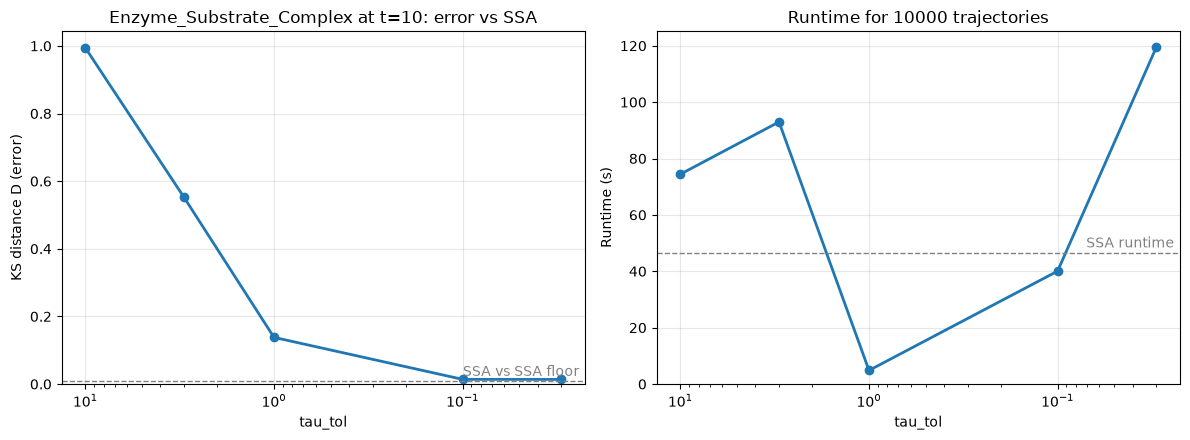

In [14]:
fig, (ax_err, ax_time) = plt.subplots(1, 2, figsize=(12, 4.5))

# error vs tolerance, with the SSA vs SSA noise floor as a reference line
ax_err.plot(tols, [ks_dist[tol] for tol in tols], marker='o', linewidth=2)
ax_err.axhline(ks_floor.statistic, color='gray', linestyle='--', linewidth=1)
ax_err.annotate('SSA vs SSA floor', xy=(1, ks_floor.statistic), xycoords=('axes fraction', 'data'),
                xytext=(-4, 4), textcoords='offset points', ha='right', color='gray')
ax_err.set_xscale('log')
ax_err.set_xlabel('tau_tol')
ax_err.set_ylabel('KS distance D (error)')
ax_err.set_title(f'{species} at t={end_t}: error vs SSA')
ax_err.set_ylim(bottom=0)

# runtime vs tolerance, SSA runtime as a reference line
ax_time.plot(tols, [hybrid_times[tol] for tol in tols], marker='o', linewidth=2)
ax_time.axhline(ssa_time, color='gray', linestyle='--', linewidth=1)
ax_time.annotate('SSA runtime', xy=(1, ssa_time), xycoords=('axes fraction', 'data'),
                 xytext=(-4, 4), textcoords='offset points', ha='right', color='gray')
ax_time.set_xscale('log')
ax_time.set_xlabel('tau_tol')
ax_time.set_ylabel('Runtime (s)')
ax_time.set_title(f'Runtime for {num_traj} trajectories')
ax_time.set_ylim(bottom=0)

for ax in (ax_err, ax_time):
    ax.invert_xaxis()  # tighter tolerance to the right
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

***
## SSA Self-Convergence
***
Independent SSA runs of the same size should overlap more as N grows. The N where they are almost the same is the N to use for the sweep.

### Config

In [15]:
from itertools import combinations

hist_Ns = [1000, 10000, 100000]  # ensemble sizes to try, smallest first
n_runs = 3                    # independent SSA runs per N (one histogram each)

### Helpers

In [16]:
def run_ssa_ensemble(n):
    """Run n SSA trajectories to end_t and return the final count of `species` for each."""
    sim = gillespy2.Simulation(model, number_of_trajectories=n, dt=dt, end_t=end_t, solver="SSA")
    vals = []
    for traj in range(n):
        sim.reset()  # reset the simulation after each run
        prev_t = -1
        while sim.get_time() < sim.end_t:
            t = sim.get_time()
            if t == prev_t:
                raise RuntimeError("Time is not advancing")
            prev_t = t
            sim.run_until(sim.get_time() + sim.dt)
        vals.append(sim.get_species(species))
    return np.array(vals)


def run_hybrid_ensemble(n, tol, step=None):
    """Run n Tau-Hybrid trajectories to end_t with tau_tol=tol and return the final count of `species` for each.

    step is how far each run_until call advances. It defaults to end_t (one call per trajectory),
    because each call's stop time caps the tau step: with step=dt=0.1 a loose tau_tol like 0.5
    gets forced down to 0.1 steps and its error never shows. Only the end_t value is kept, so
    the intermediate stops aren't needed.
    """
    step = end_t if step is None else step
    sim = gillespy2.Simulation(model, number_of_trajectories=n, dt=step, end_t=end_t, solver="HYBRID", tau_tol=tol)
    vals = []
    for traj in range(n):
        sim.reset()  # reset the simulation after each run
        prev_t = -1
        while sim.get_time() < sim.end_t:
            t = sim.get_time()
            if t == prev_t:
                raise RuntimeError("Time is not advancing")
            prev_t = t
            sim.run_until(min(sim.get_time() + step, sim.end_t))
        vals.append(sim.get_species(species))
    return np.array(vals)


def plot_overlapping_hists(groups, labels, title, colors=('red', 'blue', 'magenta')):
    """Translucent histograms drawn on the same axes, one color per group, with shared bins.
    Where the groups overlap the colors mix (red + blue -> purple), so when they come from
    the same distribution the histograms line up into one purple shape."""
    alpha = 1 / len(groups) + 0.1  # 0.6 for two groups, ~0.43 for three
    bins = np.histogram_bin_edges(np.concatenate(groups), bins='auto')
    plt.figure(figsize=(9, 4))
    for group, label, color in zip(groups, labels, colors):
        plt.hist(group, bins=np.linspace(15.5,75.5,num=61), color=color, alpha=alpha, histtype='stepfilled', label=label)
    plt.xlabel(f'{species} at t={end_t}')
    plt.ylabel('Trajectories')
    plt.title(title)
    plt.legend(loc='upper right')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

### Histograms

N=1000: max D=0.041, mean D=0.035, run means=[45.5, 45.5, 45.7], time=13.7s


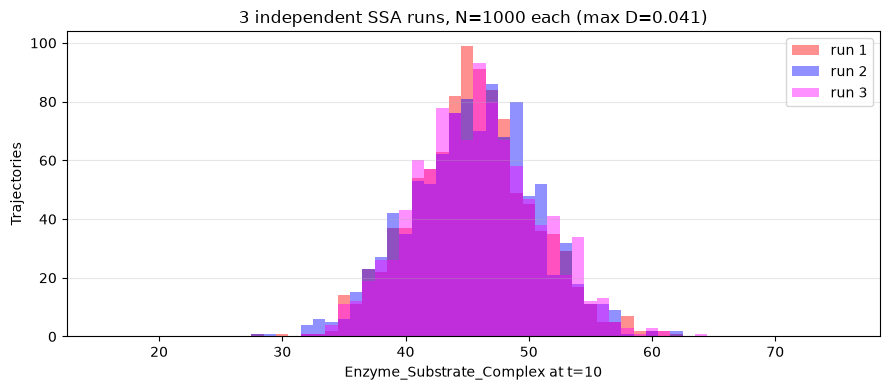

N=10000: max D=0.011, mean D=0.009, run means=[45.5, 45.5, 45.6], time=137.9s


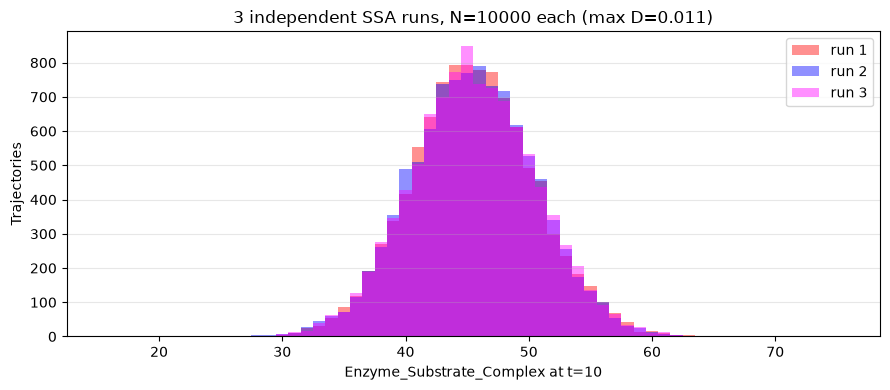

N=100000: max D=0.002, mean D=0.002, run means=[45.5, 45.5, 45.5], time=1391.4s


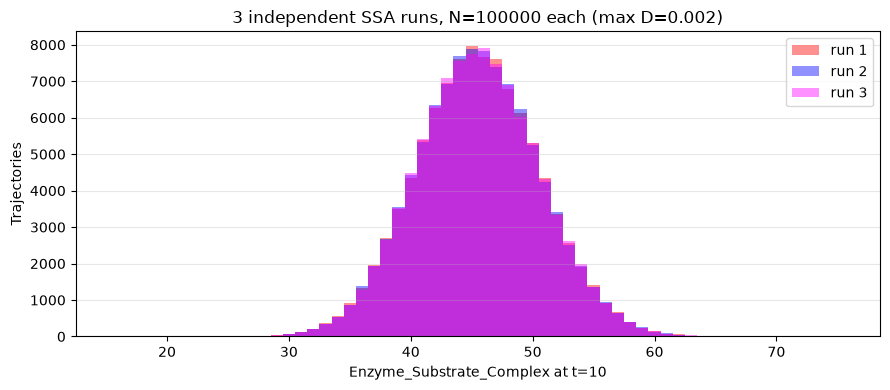

In [17]:
ssa_runs = {}  # ssa_runs[N] = list of n_runs arrays
for N in hist_Ns:
    start = time.perf_counter()
    ssa_runs[N] = [run_ssa_ensemble(N) for _ in range(n_runs)]
    elapsed = time.perf_counter() - start

    # how far apart the runs are: KS distance D for every pair of runs
    pair_d = [ks_2samp(a, b).statistic for a, b in combinations(ssa_runs[N], 2)]
    means = [run.mean() for run in ssa_runs[N]]
    print(f"N={N}: max D={max(pair_d):.3f}, mean D={np.mean(pair_d):.3f}, "
          f"run means={[round(float(m), 1) for m in means]}, time={elapsed:.1f}s")

    plot_overlapping_hists(ssa_runs[N], [f'run {r + 1}' for r in range(n_runs)],
                           f'{n_runs} independent SSA runs, N={N} each (max D={max(pair_d):.3f})')

***
## Tau-Hybrid Self-Convergence
***
The same check as the SSA section, for Tau-Hybrid at one fixed tau_tol. Independent runs should line up as N grows.

### Config

In [18]:
hybrid_tol = 0.03        # tau_tol for the hybrid self-convergence runs (the solver default)
hybrid_Ns = [1000, 10000]  # ensemble sizes for the hybrid runs; check the printed time before adding larger N

### Histograms

N=1000: max D=0.023, mean D=0.017, run means=[45.5, 45.6, 45.6], time=36.7s


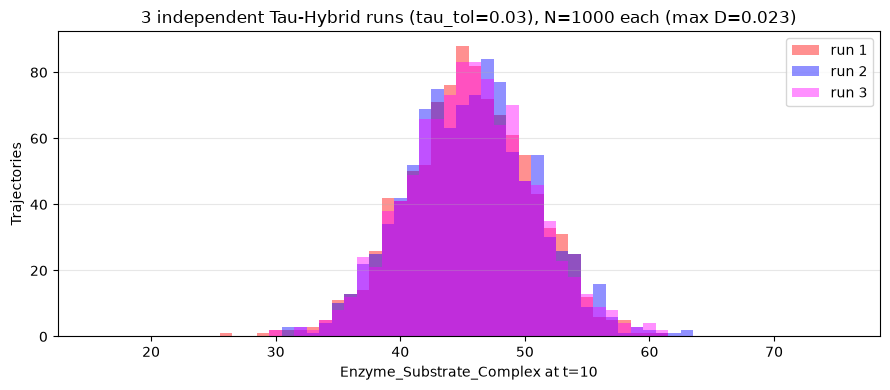

N=10000: max D=0.012, mean D=0.008, run means=[45.5, 45.5, 45.6], time=360.6s


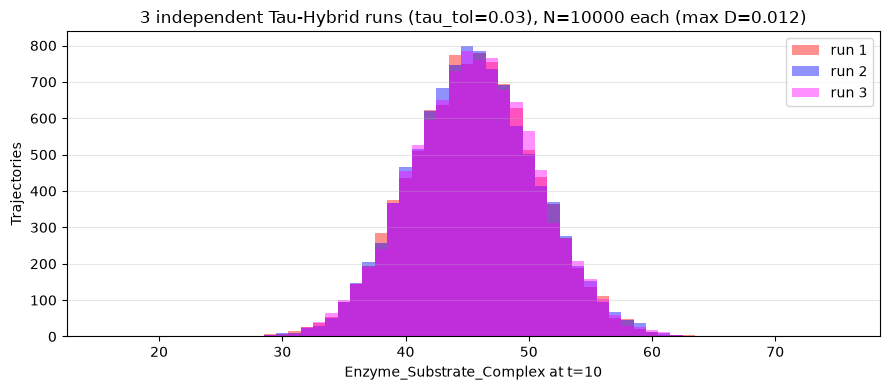

In [19]:
hybrid_runs = {}  # hybrid_runs[N] = list of n_runs arrays
for N in hybrid_Ns:
    start = time.perf_counter()
    hybrid_runs[N] = [run_hybrid_ensemble(N, hybrid_tol) for _ in range(n_runs)]
    elapsed = time.perf_counter() - start

    # how far apart the runs are: KS distance D for every pair of runs
    pair_d = [ks_2samp(a, b).statistic for a, b in combinations(hybrid_runs[N], 2)]
    means = [run.mean() for run in hybrid_runs[N]]
    print(f"N={N}: max D={max(pair_d):.3f}, mean D={np.mean(pair_d):.3f}, "
          f"run means={[round(float(m), 1) for m in means]}, time={elapsed:.1f}s")

    plot_overlapping_hists(hybrid_runs[N], [f'run {r + 1}' for r in range(n_runs)],
                           f'{n_runs} independent Tau-Hybrid runs (tau_tol={hybrid_tol}), N={N} each '
                           f'(max D={max(pair_d):.3f})')

***
## SSA vs Tau-Hybrid
***
SSA (red) and Tau-Hybrid (blue) on the same axes for each tau_tol. A large tau_tol should not match SSA; as tau_tol shrinks the histograms should move together and overlap into purple.

### Config

In [20]:
compare_tols = [1.0, 0.1, 0.03,.01,.001]  # tau_tol values, largest (least accurate) first
compare_N = 100000                        # trajectories per ensemble for the comparison

### Histograms

tau_tol=1.0: D=0.136, p=0.000, SSA mean=45.5, hybrid mean=45.2, time=5.0s


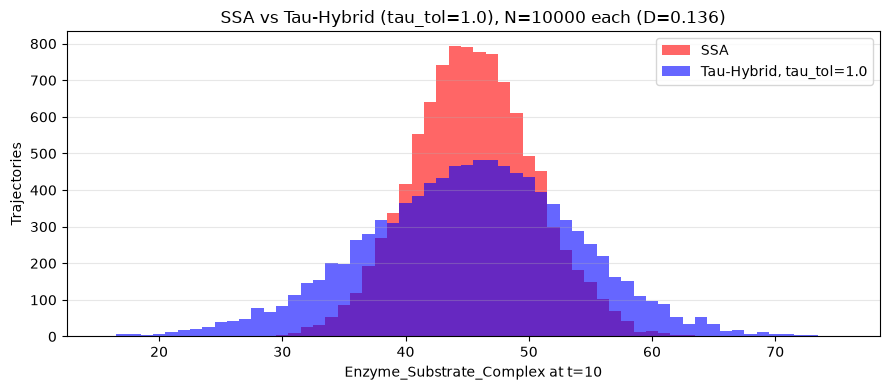

tau_tol=0.1: D=0.014, p=0.289, SSA mean=45.5, hybrid mean=45.5, time=40.9s


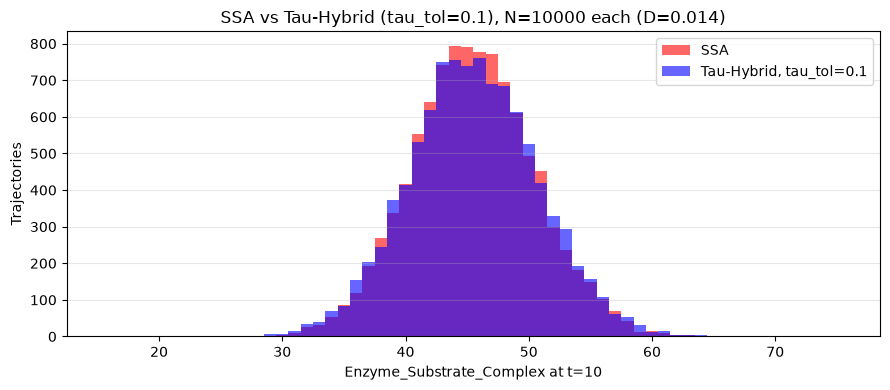

tau_tol=0.03: D=0.012, p=0.523, SSA mean=45.5, hybrid mean=45.6, time=119.2s


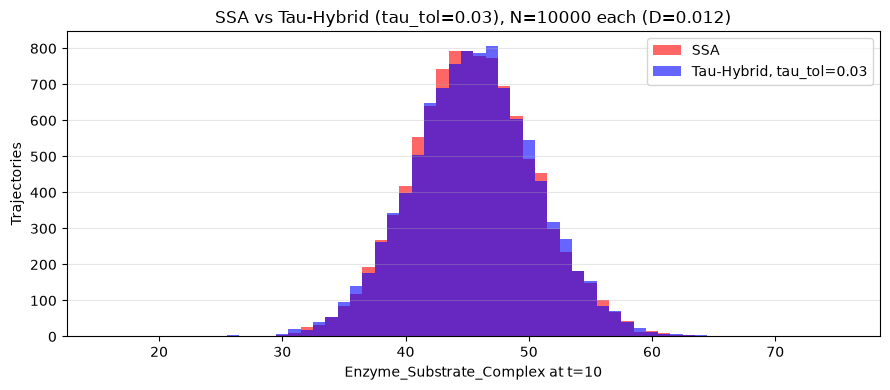

tau_tol=0.01: D=0.014, p=0.266, SSA mean=45.5, hybrid mean=45.5, time=143.5s


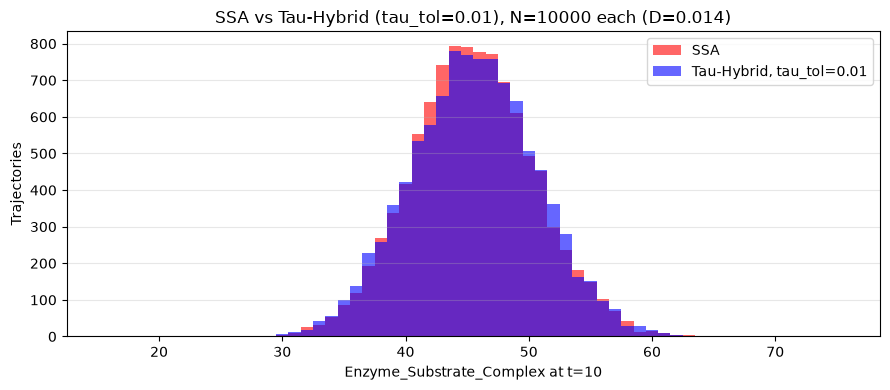

In [21]:
# SSA reference: reuse a run from the SSA self-convergence section if that size was run, else run it now
ssa_ref = ssa_runs[compare_N][0] if compare_N in ssa_runs else run_ssa_ensemble(compare_N)

compare_vals = {}  # compare_vals[tol] = Tau-Hybrid final counts at that tau_tol
for tol in compare_tols:
    start = time.perf_counter()
    compare_vals[tol] = run_hybrid_ensemble(compare_N, tol)
    elapsed = time.perf_counter() - start

    res = ks_2samp(ssa_ref, compare_vals[tol])
    print(f"tau_tol={tol}: D={res.statistic:.3f}, p={res.pvalue:.3f}, "
          f"SSA mean={ssa_ref.mean():.1f}, hybrid mean={compare_vals[tol].mean():.1f}, time={elapsed:.1f}s")

    plot_overlapping_hists([ssa_ref, compare_vals[tol]], ['SSA', f'Tau-Hybrid, tau_tol={tol}'],
                           f'SSA vs Tau-Hybrid (tau_tol={tol}), N={compare_N} each (D={res.statistic:.3f})')

***
## Large-N SSA vs Tau-Hybrid
***
One very large ensemble of each at a single tau_tol. At this N the sampling noise is small, so any remaining
gap between the histograms is real solver error rather than chance. The SSA vs SSA distance at the same N
is printed as the noise floor to compare against.

### Config

In [22]:
big_N = 100000    # trajectories per ensemble (SSA ~4.5 ms/traj, Tau-Hybrid at 0.03 ~12 ms/traj)
big_tol = 0.0003    # tau_tol for the Tau-Hybrid side (the solver default)

### Histogram

N=100000: SSA vs SSA floor D=0.0020
N=100000: SSA vs Tau-Hybrid (tau_tol=0.03) D=0.0069, p=0.0168, SSA mean=45.50, hybrid mean=45.55, time=1206.6s


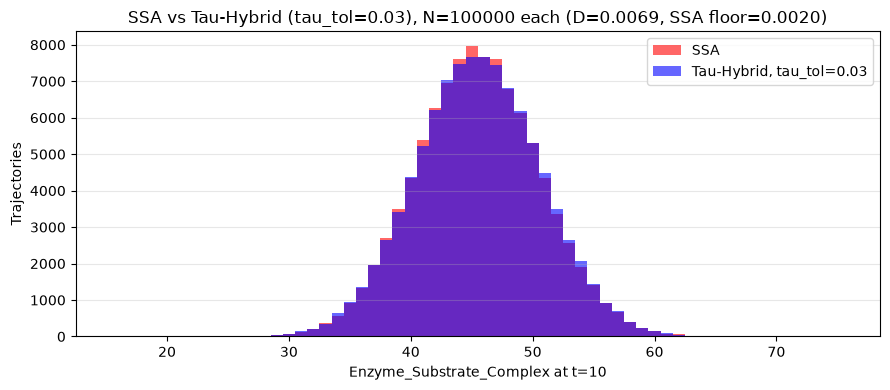

In [23]:
# reuse the SSA self-convergence runs at this N if they exist: run 1 is the reference, run 2 the noise floor
if big_N in ssa_runs:
    ssa_big, ssa_big_2 = ssa_runs[big_N][0], ssa_runs[big_N][1]
else:
    ssa_big, ssa_big_2 = run_ssa_ensemble(big_N), run_ssa_ensemble(big_N)

start = time.perf_counter()
hybrid_big = run_hybrid_ensemble(big_N, big_tol)
elapsed = time.perf_counter() - start

floor = ks_2samp(ssa_big, ssa_big_2)
res = ks_2samp(ssa_big, hybrid_big)
print(f"N={big_N}: SSA vs SSA floor D={floor.statistic:.4f}")
print(f"N={big_N}: SSA vs Tau-Hybrid (tau_tol={big_tol}) D={res.statistic:.4f}, p={res.pvalue:.3g}, "
      f"SSA mean={ssa_big.mean():.2f}, hybrid mean={hybrid_big.mean():.2f}, time={elapsed:.1f}s")

plot_overlapping_hists([ssa_big, hybrid_big], ['SSA', f'Tau-Hybrid, tau_tol={big_tol}'],
                       f'SSA vs Tau-Hybrid (tau_tol={big_tol}), N={big_N} each '
                       f'(D={res.statistic:.4f}, SSA floor={floor.statistic:.4f})')